<a href="https://colab.research.google.com/github/HamidBekamiri/BDS-Teaching/blob/main/M2_clean_extract_build_kg_run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧹➡️🔎➡️🕸️ Clean, extract, build: a knowledge graph with your own LLM

**KG session · Lab D**

A knowledge graph is only as good as the text it is built from. Real patent records are messy: one inventor is written
three ways, one city has a Danish and an English name, and the firm is hidden inside a free-text address.

This notebook does the whole job on the real EPO inventor file, with **the same code as session 2**: the `openai` package
pointed at Ollama, a Pydantic class for each answer, and `ask()` with its retry.

| Part | Job | Rules do | The LLM does |
|---|---|---|---|
| **A · Clean** | one node per real thing | capital letters, commas, ø/oe | “same person?” and “standard city name?” |
| **B · Extract** | new facts from text | the “c/o” cut from Lab A | a form for each address: firm, type, department |
| **C · Build** | the graph | triples, merge, save | nothing: every LLM triple is only marked `method="llm"` |

**Before you start:** Runtime → Change runtime type → T4 GPU. Then Runtime → Run all. The model calls take about 15 minutes
the first time; every answer is saved, so a second run is fast.

**Contents**
0. Setup and the tools from session 2
1. The data, and how messy it is
2. **A1** Clean names with rules
3. **A2** Same person? Ask the model
4. **A3** Clean city names with the model
5. **B1** Extract facts from addresses
6. **B2** Check and clean the extracted facts
7. **C1** Build the triples
8. **C2** What did cleaning change?
9. **C3** Draw the graph
10. **C4** Ask it a question

**Own machine.** The notebook also runs in Jupyter or VS Code with Ollama installed. Leave `BACKEND` on `ollama`.

**Plan B**, if local does not work: as in session 2, store a free `GEMINI_API_KEY` or `GROQ_API_KEY` as a Colab secret and set
`BACKEND` below. The records then go to the provider, and your numbers will differ from the ones in the text.

In [ ]:
# @title Setup: install Ollama and download the model (2 to 4 minutes) { display-mode: "form" }
BACKEND = "ollama"  # @param ["ollama", "gemini", "groq"]
MODEL_LOCAL = "gemma3:4b"  # @param {type:"string"}
%pip install -q -U openai 2> /dev/null
import json, os, re, shutil, subprocess, sys, time, unicodedata, warnings, itertools
from collections import Counter, defaultdict
from typing import Literal, Optional
import pandas as pd, matplotlib.pyplot as plt, networkx as nx
from openai import OpenAI
from pydantic import BaseModel
warnings.filterwarnings("ignore")

OLLAMA = "http://localhost:11434"
if BACKEND == "ollama":
    if shutil.which("ollama") is None and "google.colab" in sys.modules:
        subprocess.run("apt-get -qq install -y zstd > /dev/null && curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1", shell=True)
    if shutil.which("ollama") is None:
        raise RuntimeError("Ollama is not installed. Install it as described on Moodle, or use plan B.")
    subprocess.Popen(["ollama", "serve"], start_new_session=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(4)
    if MODEL_LOCAL not in subprocess.run(["ollama", "list"], capture_output=True, text=True).stdout:
        t0 = time.time()
        done = subprocess.run(["ollama", "pull", MODEL_LOCAL], capture_output=True)
        print(f"{MODEL_LOCAL} ready ({time.time() - t0:.0f} s)" if done.returncode == 0 else f"{MODEL_LOCAL} did not download. Use plan B.")
    BASE_URL, API_KEY, MODEL, EXTRA, PAUSE = OLLAMA + "/v1", "ollama", MODEL_LOCAL, {"reasoning_effort": "none"}, 0
else:   # plan B: the same calls go to a cloud model
    BASE_URL, secret, MODEL, EXTRA, PAUSE = {
        "gemini": ("https://generativelanguage.googleapis.com/v1beta/openai", "GEMINI_API_KEY", "gemini-flash-lite-latest", {}, 4.2),
        "groq": ("https://api.groq.com/openai/v1", "GROQ_API_KEY", "openai/gpt-oss-20b", {"reasoning_effort": "low"}, 3),
    }[BACKEND]
    try:
        from google.colab import userdata
        API_KEY = userdata.get(secret)
    except ImportError:
        API_KEY = os.environ[secret]

NAVY, LAV, ORANGE = "#211A52", "#C2C1CC", "#D2542A"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_colwidth", 90)
print(BACKEND, "·", MODEL)

Note: you may need to restart the kernel to use updated packages.


ollama · gemma3:4b


---
# 🔧 0 · The tools from session 2

`ask()` is copied unchanged. One helper is new: `ask_all()` runs `ask()` over a list and **saves every answer** in a file
named after the task and the model. Stop the notebook at any time; the next run starts where it stopped.

In [ ]:
client = OpenAI(base_url=BASE_URL, api_key=API_KEY)

def ask(system, user, schema):
    for temperature in (0, 0.2, 0.4):   # the same temperature would repeat the same mistake
        time.sleep(PAUSE)
        try:
            response = client.chat.completions.parse(
                model=MODEL,
                temperature=temperature,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}],
                response_format=schema,
                **EXTRA,
            )
            return response.choices[0].message.parsed
        except Exception as e:
            error = e
            if "429" in str(e):
                time.sleep(30)   # over the free limit: wait for the next minute
    raise error

def ask_all(task, items, system, schema):
    # items: {id: text for the model}. Returns {id: answer as a dict}, saved in a file as we go.
    path = f"{task}_{MODEL.replace(':', '_').replace('/', '_')}.json"
    saved = json.load(open(path)) if os.path.exists(path) else {}
    t0, new = time.time(), 0
    for key, text in items.items():
        if key not in saved:
            saved[key] = ask(system, text, schema).model_dump()
            new += 1
            if new % 25 == 0:
                json.dump(saved, open(path, "w"), ensure_ascii=False)
    json.dump(saved, open(path, "w"), ensure_ascii=False)
    print(f"{task}: {len(items)} answers, {new} new · {time.time() - t0:.0f} s")
    return {k: saved[k] for k in items}

---
# 📂 1 · The data, and how messy it is

The same EPO file as in the previous sessions: one row per inventor on a patent.

In [ ]:
URL = "https://raw.githubusercontent.com/hamidb201214-svg/Lectures/refs/heads/main/data/epo_inventors_clean.csv"
df = pd.read_csv(URL)
df = df.drop_duplicates(["inv_name", "app_nbr"]).reset_index(drop=True)
print(len(df), "records ·", df.inv_name.nunique(), "inventor names ·", df.app_nbr.nunique(), "patents ·",
      df.city.nunique(), "city names ·", df.ctry_code.nunique(), "countries")
df[["app_nbr", "inv_name", "address", "city", "ctry_code"]].head(4)

6194 records · 3744 inventor names · 2101 patents · 480 city names · 41 countries


,app_nbr,inv_name,address,city,ctry_code
0,EP20200150332,"VENDELBO, Allan Munk","c/o GN Hearing A/S, Att: Group IPR,Lautrupbjerg 7,DK-2750 Ballerup",Ballerup,DK
1,EP20200150357,"BRØDSGAARD, Martin","Møllevangen 4,8382 Hinnerup",NaN,DK
2,EP20200150357,"SØRENSEN, Søren Hove","Elgårdsminde 125,8382 Hinnerup",NaN,DK
3,EP20200150357,"YVES DEBRUYNE, Yannick","Rua da Cruz, 319, 3º Andar,4200-248 Porto",Porto,PT


Three kinds of mess, each with a real example from the file:

In [ ]:
def show(mask, cols, n=6):
    return df.loc[mask, cols].drop_duplicates().head(n)

print("1. One person, several spellings")
print(sorted(df.inv_name[df.inv_name.str.contains("HAWKINS|Hawkins")].unique()))
print(sorted(df.inv_name[df.inv_name.str.contains("BARBIER|Barbier")].unique()))
print("\n2. One city, several names")
print(df.city[df.city.str.contains("benhavn|Copenhagen|rhus", na=False)].value_counts().to_string())
print("\n3. The firm is hidden in free text")
show(df.address.str.contains("c/o", case=False, na=False), ["inv_name", "address"], 3)

1. One person, several spellings
['HAWKINS, Jason', 'HAWKINS, Samuel', 'HAWKINS, Samuel H.', 'Hawkins, Samuel']
['BARBIER, Lionel', 'Barbier, Lionel']

2. One city, several names
city
Copenhagen    371
Aarhus        254
Kobenhavn      60
Arhus          19
arhus           1

3. The firm is hidden in free text


,inv_name,address
0,"VENDELBO, Allan Munk","c/o GN Hearing A/S, Att: Group IPR,Lautrupbjerg 7,DK-2750 Ballerup"
4,"SEAWARD, James","c/o Vestas Patents Department,Hedeager 42,8200 Aarhus N"
45,"Leonhard Wasmer, Peter","c/o miniBOOSTER HYDRAULICS A/S,Fynsgade 3,6400 Sønderborg"


---
# 🧹 Part A · Clean

**Rule of thumb:** use rules for what is certain and cheap, the LLM for what needs judgement, and **check both**.

## A1 · Clean names with rules

Upper or lower case, extra commas, and Danish letters written two ways (ø or oe, aa or å) never make two different
people. A rule can safely fold them into one key.

In [ ]:
def plain(s):
    s = str(s).casefold().replace("ø", "o").replace("æ", "ae").replace("å", "aa").replace("oe", "o").replace("aa", "a")
    s = unicodedata.normalize("NFKD", s)
    return "".join(c for c in s if not unicodedata.combining(c))

def name_key(name):
    return " ".join(re.sub(r"[^a-z ]", " ", plain(name)).split())

df["name_key"] = df.inv_name.map(name_key)
print(df.inv_name.nunique(), "names →", df.name_key.nunique(), "after the rule")
(df.groupby("name_key").inv_name.unique().loc[lambda s: s.map(len) > 1].head(8))

3744 names → 3565 after the rule


name_key
altun safak burak                            [Altun, Safak Burak, ALTUN, Safak Burak]
andersen carsten                               [Andersen, Carsten, ANDERSEN, Carsten]
andersen kim folmer                      [ANDERSEN, Kim Folmer, Andersen, Kim Folmer]
andersen rasmus                                  [Andersen, Rasmus, ANDERSEN, Rasmus]
andersen willy lindegard    [ANDERSEN, Willy Lindegaard, ANDERSEN, Willy, Lindegaard]
angel beatrice                                     [Angel, Beatrice, ANGEL, Beatrice]
anker henrik                                           [ANKER, Henrik, Anker, Henrik]
asmul soren                                            [AASMUL, Soren, AASMUL, Søren]
Name: inv_name, dtype: object

## A2 · Same person? Ask the model

Now the hard cases: *Christensen, Lars* and *Christensen, Lars Christian*. Same person with and without a middle name? Or
two people? A rule cannot know. We make **candidate pairs** (same surname and same first given name) and let the model
judge each pair, given what the file says about each name: cities, years and co-inventors.

**Wrong merges are worse than missed ones**: merging two people invents collaborations that never happened. So the codebook
tells the model to say *no* when unsure.

In [ ]:
def surname_first(key_name):   # from the original spelling: "CHRISTENSEN, Lars Chr." -> ("christensen", "lars")
    last, _, first = key_name.partition(",")
    return name_key(last), (name_key(first).split() or [""])[0]

spelling = df.groupby("name_key").inv_name.agg(lambda s: s.value_counts().index[0])
groups = defaultdict(list)
for k, n in spelling.items():
    groups[surname_first(n)].append(k)
pairs = [(a, b) for ks in groups.values() if len(ks) > 1 for a, b in itertools.combinations(sorted(ks), 2)]
print(len(pairs), "candidate pairs")

patents = df.groupby("name_key").app_nbr.agg(set)
team = df.groupby("app_nbr").name_key.agg(set)
co_inventors = {k: set().union(*[team[p] for p in ps]) - {k} for k, ps in patents.items()}

def profile(k):
    rows = df[df.name_key == k]
    return (f"{spelling[k]}\n"
            f"  cities: {', '.join(sorted(rows.city.dropna().unique())) or 'unknown'}\n"
            f"  filing years: {', '.join(sorted(rows.app_nbr.str[2:6].unique()))}\n"
            f"  co-inventors: {'; '.join(sorted(spelling[c] for c in co_inventors[k])[:6]) or 'none'}")
print(profile(pairs[0][0]))

226 candidate pairs
ANDERSEN, Gert Karmisholt
  cities: Aarhus
  filing years: 2021
  co-inventors: CHRISTENSEN, Poul Brandt; EBRAHIMZADEHVESHAREH, Esmaeil; LUND, Torsten; NAYEBI, Kouroush; NIELSEN, John Godsk; SOLTANI, Hamid


In [ ]:
class SamePerson(BaseModel):
    same_person: bool
    reason: str

SYSTEM_PERSON = '''You decide whether two inventor names from European patent records belong to one person.
You get each name with its cities, filing years and co-inventors.
- same_person = true when the names fit together (one is a shorter or differently spelled form of the other)
  AND the other facts support it: the same or a nearby city, or shared co-inventors.
- same_person = false when the middle names clash (Jens Dahl versus Jens Bomholt), or when only the common first
  and last name connect them. If you are unsure, answer false.
- reason: one short sentence.'''

pair_text = {f"{a} | {b}": f"Name A: {profile(a)}\n\nName B: {profile(b)}" for a, b in pairs}
for key in list(pair_text)[:5]:          # five by eye first
    print(pair_text[key].replace("\n", "\n   "))
    print("   →", ask(SYSTEM_PERSON, pair_text[key], SamePerson), "\n")

Name A: ANDERSEN, Gert Karmisholt
     cities: Aarhus
     filing years: 2021
     co-inventors: CHRISTENSEN, Poul Brandt; EBRAHIMZADEHVESHAREH, Esmaeil; LUND, Torsten; NAYEBI, Kouroush; NIELSEN, John Godsk; SOLTANI, Hamid
   
   Name B: Andersen, Gert Lysgaard
     cities: unknown
     filing years: 2021
     co-inventors: Burchardi, Henrik; Jensen, Martin Falk


   → same_person=False reason='The names clash with different middle names and no shared cities or co-inventors are present.' 

Name A: ANDERSEN, Jens, Bo
     cities: Copenhagen
     filing years: 2021
     co-inventors: GIVSKOV, Michael; HOLM-JAKOBSEN, Tim; HULTQVIST, Louise, Dahl; NIELSEN, Thomas, Eiland; NILSSON, Carl, Martin, Peter; QVORTRUP, Katrine
   
   Name B: ANDERSEN, Jens Folkmar
     cities: Fredericia
     filing years: 2020
     co-inventors: MADSEN, Karsten Schack; PØRKSEN, Søren


   → same_person=False reason="The names clash with 'Folkmar' and 'Madsen' alongside different cities and co-inventors." 

Name A: ANDERSEN, Karsten Brandt
     cities: Horsholm
     filing years: 2021
     co-inventors: SKOV, Julia
   
   Name B: ANDERSEN, Karsten Egelund
     cities: Olgod
     filing years: 2020
     co-inventors: NIELSEN, Carsten


   → same_person=False reason="The middle names 'Brandt' and 'Egelund' differ, and the co-inventors are distinct." 

Name A: ANDERSEN, Kim Fälling
     cities: Ballerup
     filing years: 2021
     co-inventors: none
   
   Name B: ANDERSEN, Kim Folmer
     cities: Horsens
     filing years: 2020
     co-inventors: JENSEN, Thomas Toettrup; Jacobsen, Bo Nedergaard; SHARIFF, Shoib Ahmed; SKOUGAARD, Ander Vorm; SKOUGAARD, Anders Vorm; Thougaard, Hans-Joergen


   → same_person=False reason="The names clash with 'Folmer' versus 'Bomholt', and there are no shared co-inventors or cities to support a connection." 

Name A: ANDERSEN, Lasse Godballe
     cities: Aarhus, Hjortshoj
     filing years: 2020, 2021
     co-inventors: DIERKING, Alexander; HANSEN, Mads Boelsmand; Nielsen, Jens Bredal
   
   Name B: ANDERSEN, Lasse Hjul
     cities: Hobro
     filing years: 2021
     co-inventors: BJERG, Peter; EIRÍKSSON, Egill; KAUFFELD, Michael; MADSEN, Kenneth Bank


   → same_person=False reason='The names clash with different cities and co-inventors.' 



In [ ]:
person = ask_all("same_person", pair_text, SYSTEM_PERSON, SamePerson)
judged = pd.DataFrame([{"a": k.split(" | ")[0], "b": k.split(" | ")[1], **v} for k, v in person.items()])

# evidence from the file, not from the model
cities_of = df.groupby("name_key").city.agg(lambda s: set(s.dropna()))
judged["shared_co_inventor"] = [bool(co_inventors[a] & co_inventors[b]) for a, b in zip(judged.a, judged.b)]
judged["shared_city"] = [bool(cities_of[a] & cities_of[b]) for a, b in zip(judged.a, judged.b)]
judged["evidence"] = judged.shared_co_inventor | judged.shared_city
print(judged.same_person.sum(), "of", len(judged), "pairs judged the same person by the model")
pd.crosstab(judged.same_person, judged.evidence, margins=True)

same_person: 226 answers, 0 new · 0 s
61 of 226 pairs judged the same person by the model


evidence,False,True,All
same_person,,,
False,153,12,165
True,19,42,61
All,172,54,226


**Check.** `evidence` is computed from the file: the two names share a co-inventor or a city. Read the table: the
bottom-left cell holds pairs the model merged **without** any evidence in the file; the top-right cell holds pairs with
evidence that the model kept apart.

Now read the model's `reason` for the first group below. Small models often *claim* a shared co-inventor or city that the
file does not show. A reason is text the model wrote, not proof.

In [ ]:
pd.set_option("display.max_colwidth", 120)
cols = ["a", "b", "same_person", "shared_co_inventor", "shared_city", "reason"]
pd.concat([judged[judged.same_person & ~judged.evidence].head(5),
           judged[~judged.same_person & judged.shared_co_inventor].head(5)])[cols]

,a,b,same_person,shared_co_inventor,shared_city,reason
20,christensen lars chr,christensen lars lehmann hylling,True,False,False,"Both names and cities (Aarhus and Bagsvaerd) and co-inventor RANNES, Julie, Bille connect them."
22,christensen lars christian,christensen lars lehmann hylling,True,False,False,"Both names share the same first and last name and the filing year, with a co-inventor (Lehmann) residing in the same..."
56,hansen lars bo,hansen lars peter bilde,True,False,False,Both names are Lars Hansen and share the same city (Vejen) and filing year (2021).
65,hansen michael leth,hansen michael r s,True,False,False,"Both names are Michael Hansen, and they share the city of Bjerringbro."
69,hansen thomas lundgard,hansen thomas mejer,True,False,False,"Both names are 'HANSEN, Thomas', and they filed in the same year (2021) in nearby cities (Copenhagen and Knebel)."
16,christensen lars,christensen lars christian,False,True,True,"The names clash (Lars versus Lars Christian), and while they share some co-inventors and cities, the differing middl..."
28,cleveland cody,cleveland cody edward,False,True,True,"The middle names 'Edward' and 'Lolle' clash, and there are no shared cities or co-inventors beyond 'BOHR, Adam' and ..."
31,finan brian,finan brian patrick,False,True,False,"The names clash with Patrick as a middle name in Name B, and the co-inventor list differs."
35,hakola sami,hakola sami jukka,False,True,True,"The names clash (Sami versus Sami-Jukka) and there are no shared cities or co-inventors beyond CAPORAL DEL BARRIO, S..."
120,jorgensen jeppe,jorgensen jeppe bjorn,False,True,True,"The middle names 'Bjørn' and 'Ole' clash, suggesting separate individuals."


We merge two names only when **both** agree: the model says *same person* (it catches clashing middle names) **and** the
file shows evidence (it catches confident guesses). Merges can chain (A = B and B = C), so we use a small union-find: every
name points to one representative, and the inventor gets the spelling used most often in the file.

In [ ]:
merge = judged.same_person & judged.evidence
print(merge.sum(), "pairs merged ·", (judged.same_person & ~judged.evidence).sum(), "model merges rejected for lack of evidence")

parent = {k: k for k in spelling.index}
def root(k):
    while parent[k] != k:
        k = parent[k]
    return k
for a, b in judged.loc[merge, ["a", "b"]].itertuples(index=False):
    parent[root(b)] = root(a)

df["person"] = df.name_key.map(root)
display_name = df.groupby("person").inv_name.agg(lambda s: s.value_counts().index[0])
df["inventor"] = df.person.map(display_name)
print(df.inv_name.nunique(), "names →", df.name_key.nunique(), "after rules →", df.inventor.nunique(), "after the model")
df[df.inv_name.str.contains("HAWKINS|Hawkins")][["inv_name", "inventor"]].drop_duplicates()

42 pairs merged · 19 model merges rejected for lack of evidence


3744 names → 3565 after rules → 3524 after the model


,inv_name,inventor
39,"HAWKINS, Samuel H.","HAWKINS, Samuel H."
1743,"HAWKINS, Samuel","HAWKINS, Samuel H."
1845,"HAWKINS, Jason","HAWKINS, Jason"
1910,"Hawkins, Samuel","HAWKINS, Samuel H."


## A3 · Clean city names with the model

*Kobenhavn* is *Copenhagen*; *Arhus* is *Aarhus*. A list of every spelling would be long and never complete, but a language
model knows place names. The danger is the opposite mistake: turning a small town into a bigger one with a similar name.
So the codebook is **conservative**: fix letters, translate only big cities, and when unsure return the name unchanged.

In [ ]:
class City(BaseModel):
    standard_name: str

SYSTEM_CITY = '''You clean one city name from a European patent record. You get the name and its country code.
- standard_name: the same place, correctly spelled, with normal capital letters and local letters (ø, æ, å, ä, ö, ü).
  Use an English name only for capitals and large cities that have one (Kobenhavn -> Copenhagen, Munchen -> Munich, Wien -> Vienna).
- Never turn a name into a different town, even one that looks similar or is bigger and nearby. Keep suburbs and districts as they are.
- If you do not know the place, return the name exactly as given.'''

places = df.dropna(subset=["city"]).drop_duplicates(["city", "ctry_code"])
city_text = {f"{c} | {k}": f"{c}, {k}" for c, k in zip(places.city, places.ctry_code)}
city_answer = ask_all("city", city_text, SYSTEM_CITY, City)

city_map = {}
for key, ans in city_answer.items():
    city, country = key.split(" | ")
    new = ans["standard_name"].strip()
    city_map[(city, country)] = new if new else city   # an empty answer keeps the original

df["city_clean"] = [city_map.get((c, k), c) if isinstance(c, str) else None for c, k in zip(df.city, df.ctry_code)]
letters = lambda s: re.sub(r"[^a-z]", "", plain(s))
changed = (df.dropna(subset=["city"]).loc[lambda x: x.city != x.city_clean]
           .groupby(["city", "city_clean", "ctry_code"]).size().rename("records").reset_index()
           .sort_values("records", ascending=False))
changed["kind"] = ["letters only" if letters(a) == letters(b) else "renamed" for a, b in zip(changed.city, changed.city_clean)]
print(df.city.nunique(), "city names →", df.city_clean.nunique(), "after cleaning")
print(changed.kind.value_counts().to_string())

city: 480 answers, 0 new · 0 s
480 city names → 476 after cleaning
kind
letters only    14
renamed         12


**Check by eye.** A *letters only* change (capitals, ø for o) cannot move a place. A *renamed* change can, so read every one
below. A translation (Kobenhavn → Copenhagen) is fine; a town turned into another town is a mistake.

In [ ]:
pd.set_option("display.max_rows", 100)
changed[changed.kind == "renamed"]

,city,city_clean,ctry_code,records,kind
7,Kobenhavn,Copenhagen,DK,60,renamed
11,No,DK,DK,16,renamed
22,Vienna,Wien,AT,6,renamed
5,Ii,Helsinki,FI,6,renamed
21,Vallensbaek,Vallensbæck,DK,3,renamed
14,San Jose Ca,"San Jose, CA, US",US,2,renamed
1,Den Haag,The Hague,NL,1,renamed
15,Shrewsbury Massachusetts,Shrewsbury,US,1,renamed
8,Kostelec Na Hane,Kostelec nad Hanou,CZ,1,renamed
4,Havdrup,Havedrup,DK,1,renamed


Write every mistake into `FIX` (original name → the name you want) and run the cell. The entries below are the mistakes
the model made **in our run**; your model will make others, so read your own table above and add them.

In [ ]:
FIX = {                        # original name -> the name you want (None = unknown)
    "No": None,                # not a city: EPO took the district letters of "Odense NØ" and "Randers NØ"
    "Ii": "Ii",                # a real town in Finland, not Helsinki
    "Vallensbaek": "Vallensbæk",
    "San Jose Ca": "San Jose",
    "Havdrup": "Havdrup",
    "Halle Westf": "Halle (Westfalen)",
    "Village Neuf": "Village-Neuf",
    "Arhus": "Aarhus",         # missed: the model kept the old spelling
    "Munchen": "Munich",       # missed
}
df["city_clean"] = [FIX.get(c, n) for c, n in zip(df.city, df.city_clean)]

merged = df.dropna(subset=["city"]).groupby(["city_clean", "ctry_code"]).city.unique()
print("Places that now combine several original names:")
print(merged[merged.map(len) > 1].to_string())

Places that now combine several original names:
city_clean  ctry_code
Aarhus      DK            [Aarhus, arhus, Arhus]
Copenhagen  DK           [Copenhagen, Kobenhavn]
Munich      DE                 [Munchen, Munich]
Wien        AT                    [Wien, Vienna]


---
# 🔎 Part B · Extract

## B1 · Extract facts from addresses

Same form as Lab C: when an address says *c/o* (care of), the inventor is reached through an organisation. The model fills
in five fields. We add 30 home addresses as a check: those have no organisation, so any firm found there is invented.

In [ ]:
class Address(BaseModel):
    firm: Optional[str]
    org_type: Literal["company", "university", "hospital", "research institute", "other", "none"]
    department: Optional[str]
    city: Optional[str]
    country_code: Optional[str]

SYSTEM_ADDRESS = '''You read one inventor address from a European patent and fill in a form.
- firm: the company, university, hospital or other organisation the inventor is reached through, usually written after "c/o".
  Copy the name as written, with its legal form (A/S, ApS, GmbH, Ltd ...), but without street, department or person. None if there is no organisation.
- org_type: company, university, hospital, research institute, other, or none if there is no organisation.
- department: a department, unit or person inside the organisation, for example "Patent Department" or "Group IPR". None if not stated.
- city: the city of the address, as written, without postal code or district letters.
- country_code: the ISO 3166 two-letter code of the country of the address, for example DK, DE, GB.
Use None for anything not in the text. Never guess.'''

has_co = df.address.str.contains("c/o", case=False, na=False)
co_addresses = df.loc[has_co, "address"].drop_duplicates().tolist()
home_addresses = df.loc[~has_co, "address"].dropna().drop_duplicates().sample(30, random_state=1).tolist()
print(len(co_addresses), "distinct c/o addresses + 30 home addresses")

for a in co_addresses[:3]:                     # three by eye first
    print(a, "\n   →", ask(SYSTEM_ADDRESS, a, Address))

132 distinct c/o addresses + 30 home addresses


c/o GN Hearing A/S, Att: Group IPR,Lautrupbjerg 7,DK-2750 Ballerup 
   → firm='GN Hearing A/S' org_type='company' department='Group IPR' city='Ballerup' country_code='DK'


c/o Vestas Patents Department,Hedeager 42,8200 Aarhus N 
   → firm='Vestas Patents Department' org_type='other' department='Vestas Patents Department' city='Aarhus' country_code='DK'


c/o miniBOOSTER HYDRAULICS A/S,Fynsgade 3,6400 Sønderborg 
   → firm='miniBOOSTER HYDRAULICS A/S' org_type='company' department='None' city='Sønderborg' country_code='DK'


In [ ]:
address_answer = ask_all("address", {a: a for a in co_addresses + home_addresses}, SYSTEM_ADDRESS, Address)
facts = pd.DataFrame.from_dict(address_answer, orient="index").rename_axis("address").reset_index()
facts["co"] = facts.address.isin(co_addresses)
facts.head()

address: 162 answers, 0 new · 0 s


,address,firm,org_type,department,city,country_code,co
0,"c/o GN Hearing A/S, Att: Group IPR,Lautrupbjerg 7,DK-2750 Ballerup",GN Hearing A/S,company,Group IPR,Ballerup,DK,True
1,"c/o Vestas Patents Department,Hedeager 42,8200 Aarhus N",Vestas Patents Department,other,Vestas Patents Department,Aarhus,DK,True
2,"c/o miniBOOSTER HYDRAULICS A/S,Fynsgade 3,6400 Sønderborg",miniBOOSTER HYDRAULICS A/S,company,None,Sønderborg,DK,True
3,"c/o VKR Holding A/S,Breeltevej 18,2970 Hørsholm",VKR Holding A/S,company,None,Hørsholm,DK,True
4,"c/o Tophøj & Grathwol ApS,Valdemarshaab 11,4600 Køge",Tophøj & Grathwol ApS,company,None,Køge,DK,True


## B2 · Check and clean the extracted facts

Model output is data, so it gets cleaned too. Three steps.

**1. Empty values.** Small models sometimes write the word “None” instead of leaving a field empty.

In [ ]:
for col in ["firm", "department", "city", "country_code"]:
    words = facts[col].fillna("").str.strip().str.lower()
    print(f"{col:13s} written as a word: {words.isin(['none', 'null', 'n/a']).sum()}")
    facts[col] = facts[col].where(~words.isin(["", "none", "null", "n/a"]), None)

firm          written as a word: 32
department    written as a word: 148
city          written as a word: 0
country_code  written as a word: 0


**2. Check against data we trust.** The EPO cleaned the city and country columns itself, so they are an answer key. And the
home addresses tell us how often the model invents a firm.

In [ ]:
def norm(s):
    return re.sub(r"[^a-z0-9]", "", plain(s)) if isinstance(s, str) else ""

gold = df.drop_duplicates("address").set_index("address")[["city", "ctry_code"]]
co = facts[facts.co].merge(gold.rename(columns={"city": "epo_city"}), left_on="address", right_index=True)
print(f"city matches EPO:    {(co.city.map(norm) == co.epo_city.map(norm))[co.epo_city.notna()].mean():.0%}")
print(f"country matches EPO: {(co.country_code.fillna('').str.upper() == co.ctry_code).mean():.0%}")
home = facts[~facts.co]
print(f"firm invented for {home.firm.notna().sum()} of {len(home)} home addresses")
home.loc[home.firm.notna(), ["address", "firm"]].head()

city matches EPO:    88%
country matches EPO: 98%
firm invented for 2 of 30 home addresses


,address,firm
138,"F-27 Panchsheel Garden Shahdara,110032 Delhi",Panchsheel Garden
155,"Symbion Bioscience Park Fruebjergvej 3,2100 Copenhagen",Symbion Bioscience Park


**3. One firm, one name.** The model copies names as written, so *ROCKWOOL International A/S* and *ROCKWOOL INTERNATIONAL S/A*
are two strings. A key without capitals, punctuation and legal form merges them. Each firm gets its most common spelling.

Note what the key decides for you: *Genmab A/S* (Denmark) and *Genmab B.V.* (the Netherlands) become one node. That is the group, not the legal company. Either can be right; write down which one you chose.

In [ ]:
FORMS = r"\b(a/?s|s/?a|aps|gmbh|ab|oy|inc|ltd|limited|ag|b\.?\s?v|n\.?\s?v|plc|llc|corp|corporation|co)\b\.?"
def firm_key(name):
    if not isinstance(name, str):
        return None
    k = re.sub(FORMS, " ", name.casefold())
    return " ".join(re.sub(r"[^a-z0-9æøåäöü ]", " ", k).split()) or None

co["firm_key"] = co.firm.map(firm_key)
firm_name = co.dropna(subset=["firm_key"]).groupby("firm_key").firm.agg(lambda s: s.value_counts().index[0])
print(co.firm.nunique(), "firm spellings →", len(firm_name), "firms")
co.dropna(subset=["firm_key"]).groupby("firm_key").firm.unique().loc[lambda s: s.map(len) > 1].head(6)

91 firm spellings → 82 firms


firm_key
arla foods amba                                                             [Arla Foods Amba, ARLA FOODS AMBA]
chr hansen                                                                 [Chr. Hansen A/S, Chr. Hansen Inc.]
foss analytical                                                     [FOSS Analytical A/S, Foss Analytical A/S]
genmab                                                                 [Genmab B.V., Genmab A/S, Genmab B. V.]
grundfos holding                                                      [Grundfos Holding A/S, Grundfos Holding]
rockwool international    [ROCKWOOL International A/S, ROCKWOOL INTERNATIONAL A/S, ROCKWOOL International S/A]
Name: firm, dtype: object

---
# 🕸️ Part C · Build

## C1 · Build the triples

A knowledge graph is a table of triples: **subject · relation · object**. We add two columns that every serious KG needs:
`method` (where the fact came from: the `file` or the `llm`) and `source` (the record or address that supports it).
Cleaned names are used everywhere, so each person and each city is **one** node.

In [ ]:
by_address = co.dropna(subset=["firm_key"]).set_index("address")
rows = []
def triple(s, s_type, rel, o, o_type, method, source):
    rows.append(dict(subject=s, s_type=s_type, relation=rel, object=o, o_type=o_type, method=method, source=source))

for r in df.itertuples():
    triple(r.inventor, "Inventor", "INVENTED", r.app_nbr, "Patent", "file", r.app_nbr)
    if isinstance(r.city_clean, str):
        triple(r.inventor, "Inventor", "LIVES_IN", r.city_clean, "City", "file", r.app_nbr)
        triple(r.city_clean, "City", "IN_COUNTRY", r.ctry_code, "Country", "file", r.app_nbr)
    if r.address in by_address.index:
        f = by_address.loc[r.address]
        triple(r.inventor, "Inventor", "AFFILIATED_WITH", firm_name[f.firm_key], "Firm", "llm", r.address)
        triple(firm_name[f.firm_key], "Firm", "IS_A", f.org_type, "OrgType", "llm", r.address)
        if isinstance(f.department, str):
            triple(r.inventor, "Inventor", "REACHED_VIA", f"{f.department.strip()} ({firm_name[f.firm_key]})", "Department", "llm", r.address)

triples = (pd.DataFrame(rows).groupby(["subject", "s_type", "relation", "object", "o_type", "method"], as_index=False)
           .agg(sources=("source", "nunique")))      # one row per fact, with how many records support it
triples.to_csv("kg_triples.csv", index=False)
print(len(triples), "triples saved to kg_triples.csv\n")
print(triples.groupby(["relation", "method"]).size().rename("triples").to_string())
triples.sample(5, random_state=2)

10300 triples saved to kg_triples.csv

relation         method
AFFILIATED_WITH  llm        353
INVENTED         file      6194
IN_COUNTRY       file       474
IS_A             llm         82
LIVES_IN         file      3175
REACHED_VIA      llm         22


,subject,s_type,relation,object,o_type,method,sources
338,"AZAR, Ziad",Inventor,INVENTED,EP20200209447,Patent,file,1
9993,"WU, Rui",Inventor,INVENTED,EP20210725695,Patent,file,1
8928,"Subramanian Kalyanaraman, Haritha",Inventor,INVENTED,EP20200178878,Patent,file,1
5720,"Lauridsen, Mads",Inventor,INVENTED,EP20210789646,Patent,file,1
3614,"Haugaard, Mikkel",Inventor,INVENTED,EP20200182465,Patent,file,1


## C2 · What did cleaning change?

Build the same graph from the **raw** names and cities and compare. Fewer nodes is not the goal; one node per real thing is.

In [ ]:
KG = nx.MultiDiGraph()
for t in triples.itertuples():
    KG.add_node(t.subject, type=t.s_type); KG.add_node(t.object, type=t.o_type)
    KG.add_edge(t.subject, t.object, rel=t.relation, method=t.method)

compare = pd.DataFrame({
    "raw": {"Inventor": df.inv_name.nunique(), "City": df.city.nunique()},
    "after rules": {"Inventor": df.name_key.nunique(), "City": df.city.str.strip().str.title().nunique()},
    "after the LLM": {"Inventor": df.inventor.nunique(), "City": df.city_clean.nunique()},
})
print(compare.to_string(), "\n")

for city in ["Copenhagen", "Aarhus"]:
    raw = df[df.city_clean == city]
    print(f"{city}: {raw.city.nunique()} raw names {sorted(raw.city.unique())} → one node with {raw.inventor.nunique()} inventors")

           raw  after rules  after the LLM
Inventor  3744         3565           3524
City       480          479            474 

Copenhagen: 2 raw names ['Copenhagen', 'Kobenhavn'] → one node with 334 inventors
Aarhus: 3 raw names ['Aarhus', 'Arhus', 'arhus'] → one node with 192 inventors


In [ ]:
best_raw = df.groupby(["inventor", "inv_name"]).app_nbr.nunique().groupby("inventor").max()   # largest single spelling
after = df.groupby("inventor").app_nbr.nunique()
gain = pd.DataFrame({"patents, best spelling": best_raw, "patents, merged": after,
                     "spellings": df.groupby("inventor").inv_name.nunique()})
gain["gained"] = gain["patents, merged"] - gain["patents, best spelling"]
print("Inventors who gained the most patents from merging their name variants:")
gain.sort_values("gained", ascending=False).head(6)

Inventors who gained the most patents from merging their name variants:


,"patents, best spelling","patents, merged",spellings,gained
inventor,,,,
"Wigard, Jeroen",14,22,2,8
"Lauridsen, Mads",13,20,2,7
"KOVÁCS, István Zsolt",7,14,6,7
"LASELVA, Daniela",22,29,2,7
"VEJLGAARD, Benny",24,30,2,6
"Hoegh, Gustav",12,18,2,6


## C3 · Draw the graph

The whole graph has thousands of nodes. We draw **one firm's corner**: the firm, its inventors, their patents, their
co-inventors, where everyone lives, and the countries. Orange ties come from the model, grey ties from the file.

In [ ]:
firms = [n for n, t in KG.nodes(data="type") if t == "Firm"]
def nbrs(n, rel, incoming=False):
    edges = KG.in_edges(n, data="rel") if incoming else KG.out_edges(n, data="rel")
    return {(u if incoming else v) for u, v, k in edges if k == rel}

def corner(firm):
    staff = nbrs(firm, "AFFILIATED_WITH", incoming=True)
    pats = set().union(*[nbrs(i, "INVENTED") for i in staff])
    people = set().union(*[nbrs(p, "INVENTED", incoming=True) for p in pats])
    cities = set().union(*[nbrs(i, "LIVES_IN") for i in people])
    countries = set().union(*[nbrs(c, "IN_COUNTRY") for c in cities])
    return staff, pats, people - staff, cities, countries

size = {f: sum(map(len, corner(f))) for f in firms}
pick = max((f for f in firms if size[f] <= 70), key=lambda f: (len(corner(f)[4]), size[f]))
staff, pats, others, cities, countries = corner(pick)
print(pick, "·", len(staff), "affiliated inventors ·", len(pats), "patents ·", len(countries), "countries")

Chr. Hansen A/S · 15 affiliated inventors · 14 patents · 4 countries


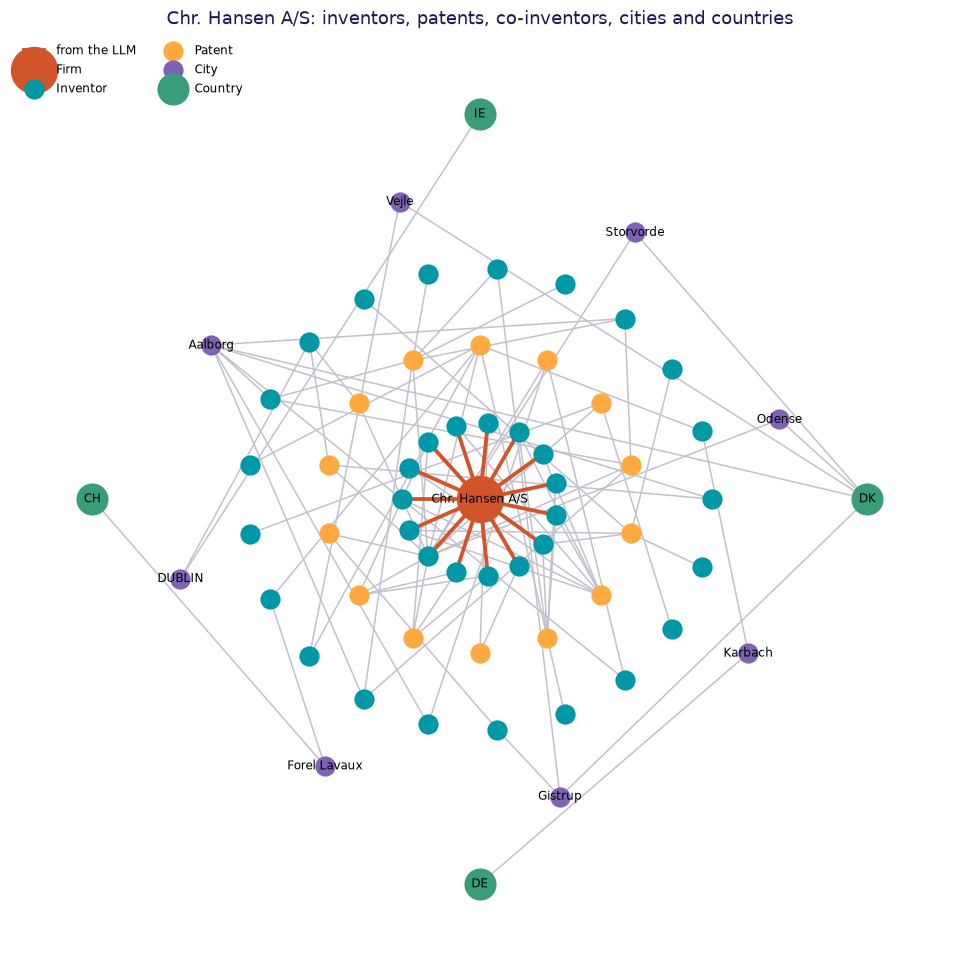

In [ ]:
H = nx.DiGraph(KG.subgraph({pick, *staff, *pats, *others, *cities, *countries}))
shells = [[pick], sorted(staff), sorted(pats), sorted(others), sorted(cities), sorted(countries)]
pos = nx.shell_layout(H, [s for s in shells if s])
COLOURS = {"Firm": ORANGE, "Inventor": "#0097A7", "Patent": "#FFA940", "City": "#7E62B3", "Country": "#3A9D7A"}

fig, ax = plt.subplots(figsize=(11, 11))
llm = [(u, v) for u, v in H.edges if KG.has_edge(u, v) and any(d["method"] == "llm" for d in KG.get_edge_data(u, v).values())]
nx.draw_networkx_edges(H, pos, edgelist=[e for e in H.edges if e not in llm], edge_color=LAV, arrows=False, ax=ax)
nx.draw_networkx_edges(H, pos, edgelist=llm, edge_color=ORANGE, width=2.5, arrows=False, ax=ax, label="from the LLM")
for t, c in COLOURS.items():
    nodes = [n for n in H if H.nodes[n]["type"] == t]
    nx.draw_networkx_nodes(H, pos, nodelist=nodes, node_color=c, label=t, ax=ax,
                           node_size=900 if t == "Firm" else 400 if t == "Country" else 150)
nx.draw_networkx_labels(H, pos, {n: n for n in H if H.nodes[n]["type"] in ("Firm", "City", "Country")}, font_size=8, ax=ax)
ax.legend(frameon=False, loc="upper left", fontsize=8, ncol=2)
ax.set_title(f"{pick}: inventors, patents, co-inventors, cities and countries", color=NAVY)
ax.axis("off")
plt.show()

## C4 · Ask it a question

**Which firms have inventors in more than one country?** The answer needs four relations from three sources: AFFILIATED_WITH
(the LLM), INVENTED and LIVES_IN (the file, with cleaned names), IN_COUNTRY (the file). No one-mode or two-mode network can
answer it.

In [ ]:
answer = pd.DataFrame([{"firm": f, "type": next(iter(nbrs(f, "IS_A")), "?"),
                        "inventors": len(corner(f)[0]), "patents": len(corner(f)[1]),
                        "countries": " · ".join(sorted(corner(f)[4]))} for f in firms])
answer["n_countries"] = answer.countries.str.count("·") + 1
cross = answer[answer.n_countries > 1].sort_values(["n_countries", "patents"], ascending=False)
print(f"{len(cross)} of {len(firms)} firms have inventors in more than one country")
cross.drop(columns="n_countries").head(10)

27 of 82 firms have inventors in more than one country


,firm,type,inventors,patents,countries
1,LM Wind Power A/S,company,17,25,DE · DK · ES · GB
36,Chr. Hansen A/S,company,15,14,CH · DE · DK · IE
6,Danmarks Tekniske Universitet,university,24,19,DE · DK · JP
27,Blade Dynamics Limited,company,4,9,DE · DK · GB
7,Genmab B.V.,company,19,6,DE · DK · NL
13,UNION therapeutics A/S,company,7,6,DE · DK · JP
76,Vestas Wind Systems A/S,company,5,6,DE · DK · PT
65,Roche Innovation Center Copenhagen A/S,company,4,5,CH · DE · DK
52,"Genmab US, Inc.",company,3,3,DE · DK · NL
80,Vestas Patents Department,other,3,3,DK · GB · PT


🤔 *Every row rests on at least one `method="llm"` triple. Report the answer as “at least”, and say how you checked the
extraction (B2) and the merges (A2).*

---
# ✏️ Your turn

1. **Who decides a merge?** Merge on the model alone (`merge = judged.same_person`), then on the evidence alone
   (`merge = judged.evidence`). How many inventors do you get each time, and which Christensens change in C2?
2. **Read the city changes.** Find one city change in A3 you disagree with, add it to `FIX`, and rerun from A3.
3. **A new relation.** Add `is_ip_department: bool` to the address form. Which firms route inventors through an IP department?
4. **With and without the LLM.** Rerun C4 using only triples with `method == "file"` plus the Lab A rule for firms. Which firms
   appear only thanks to the model?

---
# 🧭 The recipe

**Clean** with rules first, then the model for judgement calls, and check against outside evidence ·
**extract** with a form and a codebook, five by eye, then all, saving as you go ·
**check** the output against data you trust and clean it like any other data ·
**build** triples with `method` and `source` on every fact, so each result can be reported with and without the model.